In [2]:
from pathlib import Path
import json
import pandas as pd
from pathlib import Path
import seaborn as sns
import matplotlib.pyplot as plt

base_path = Path("./")
datasets = ['imdb', 'cora', 'twitter', 'nell_finances', 'nell_sports', 'yeast', 'uwcse']

## Small Datasets - Original RDN Boost

In [3]:
records = []

for dataset in datasets:
    file_name = base_path / f"small_dataset_results_original_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)
    
    for experiment in data:
        for r in experiment.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})
            record = {
                "dataset": dataset,
                **{f"train_{k}": v for k, v in train.items()},
                **{f"test_{k}": v for k, v in test.items()},
            }
            records.append(record)

# Cria o DataFrame com todos os resultados
df = pd.DataFrame(records)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Agrupa por dataset e calcula média e desvio
grouped = df.groupby("dataset").agg(["mean", "std"])

# Achata o MultiIndex das colunas
grouped.columns = [f"{col[0]}_{col[1]}" for col in grouped.columns]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=grouped.index)

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = grouped.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )

formatted.reset_index(inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.589 ± 0.049,0.557 ± 0.011,0.521 ± 0.125,0.477 ± 0.036
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.775 ± 0.038,0.721 ± 0.049,0.694 ± 0.049,0.632 ± 0.058
3,nell_sports,0.999 ± 0.001,0.988 ± 0.006,0.998 ± 0.001,0.964 ± 0.023
4,twitter,0.992 ± 0.007,0.991 ± 0.004,0.984 ± 0.014,0.975 ± 0.010
5,uwcse,0.980 ± 0.011,0.919 ± 0.036,0.961 ± 0.022,0.779 ± 0.087
6,yeast,0.944 ± 0.049,0.913 ± 0.053,0.922 ± 0.061,0.874 ± 0.064


## Large Datasets - Original RDN Boost

In [8]:
records = []

for dataset in datasets:
    file_name = base_path / f"large_dataset_results_original_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)
    
    for experiment in data:
        for r in experiment.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})
            record = {
                "dataset": dataset,
                **{f"train_{k}": v for k, v in train.items()},
                **{f"test_{k}": v for k, v in test.items()},
            }
            records.append(record)

# Cria o DataFrame com todos os resultados
df = pd.DataFrame(records)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Agrupa por dataset e calcula média e desvio
grouped = df.groupby("dataset").agg(["mean", "std"])

# Achata o MultiIndex das colunas
grouped.columns = [f"{col[0]}_{col[1]}" for col in grouped.columns]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=grouped.index)

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = grouped.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )

formatted.reset_index(inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.572 ± 0.008,0.579 ± 0.059,0.504 ± 0.021,0.512 ± 0.117
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.759 ± 0.029,0.704 ± 0.064,0.676 ± 0.038,0.617 ± 0.078
3,nell_sports,0.999 ± 0.000,0.991 ± 0.004,0.997 ± 0.001,0.988 ± 0.006
4,twitter,0.991 ± 0.008,0.991 ± 0.006,0.982 ± 0.015,0.978 ± 0.013
5,uwcse,0.974 ± 0.007,0.940 ± 0.040,0.941 ± 0.016,0.855 ± 0.089
6,yeast,0.878 ± 0.067,0.861 ± 0.082,0.838 ± 0.082,0.818 ± 0.100


## Small Datasets - GFL RDN Boost

Check RDN simulation

In [5]:
records = []

for dataset in datasets:
    file_name = base_path / f"small_dataset_results_gfl_{dataset}_rdn_simulation.json"
    
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=summary.index)
formatted["dataset"] = summary["dataset"]

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = summary.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )
formatted.reset_index(drop=True, inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.589 ± 0.050,0.556 ± 0.011,0.520 ± 0.127,0.477 ± 0.035
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.783 ± 0.037,0.731 ± 0.044,0.702 ± 0.047,0.644 ± 0.053
3,nell_sports,0.999 ± 0.001,0.988 ± 0.006,0.998 ± 0.001,0.963 ± 0.024
4,twitter,0.994 ± 0.006,0.992 ± 0.004,0.987 ± 0.012,0.978 ± 0.010
5,uwcse,0.980 ± 0.012,0.919 ± 0.036,0.960 ± 0.023,0.781 ± 0.088
6,yeast,0.932 ± 0.058,0.898 ± 0.070,0.905 ± 0.073,0.854 ± 0.084


In [6]:
records = []

for dataset in datasets:
    file_name = base_path / f"small_dataset_results_gfl_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        print(exp)
        gamma = exp.get("focal_loss_gamma")
        lambd = exp.get("boxcox_lambda")

        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "gamma": gamma,
                "lambda": lambd,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset", "gamma", "lambda"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

#display(summary.head())


FileNotFoundError: [Errno 2] No such file or directory: 'small_dataset_results_gfl_imdb.json'


📊 Dataset: cora


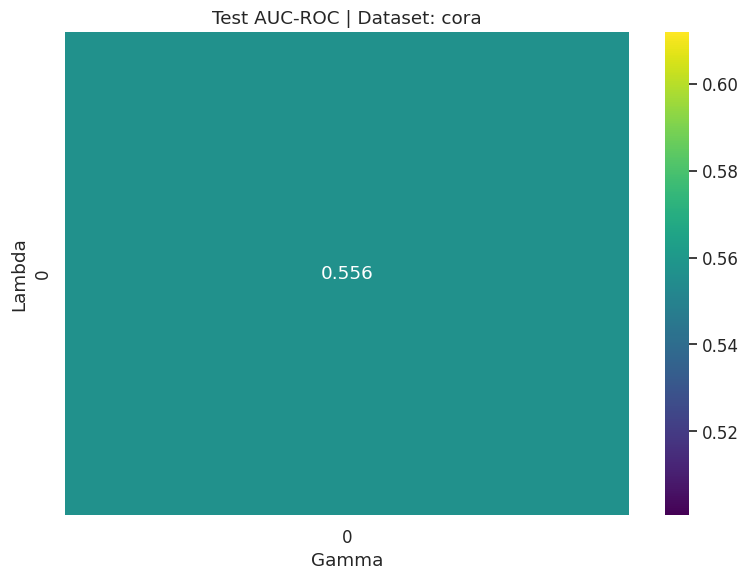


📊 Dataset: imdb


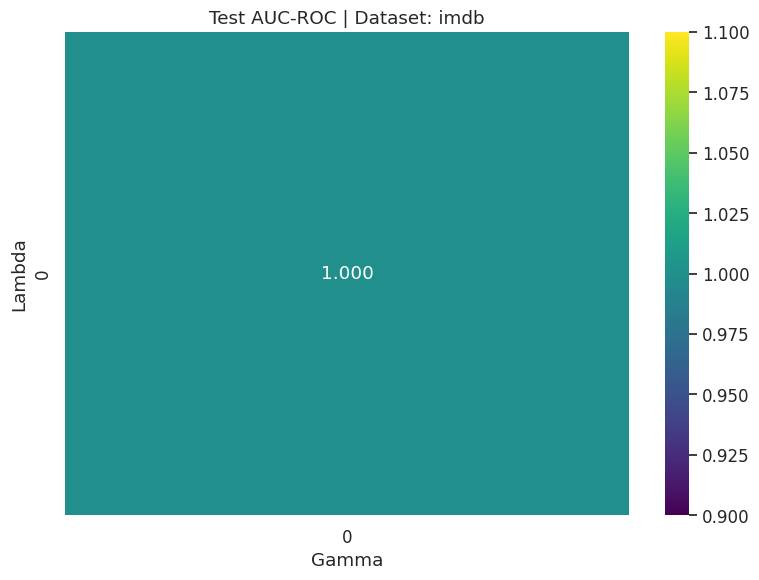


📊 Dataset: nell_finances


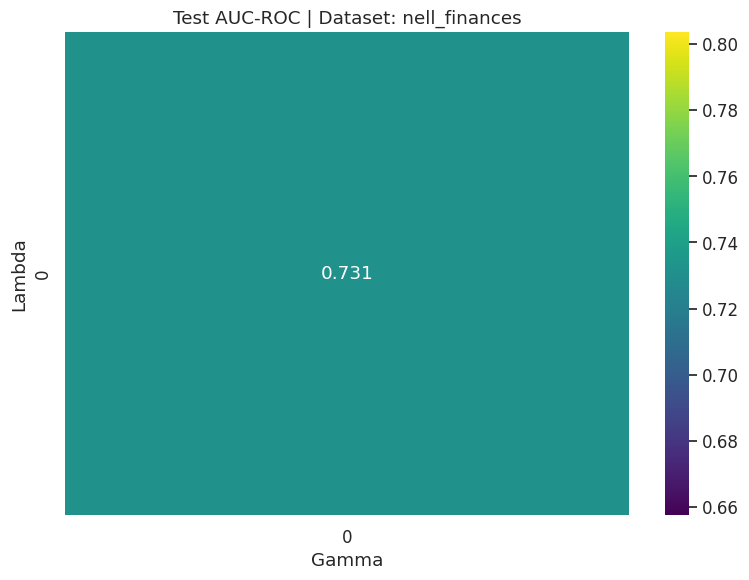


📊 Dataset: nell_sports


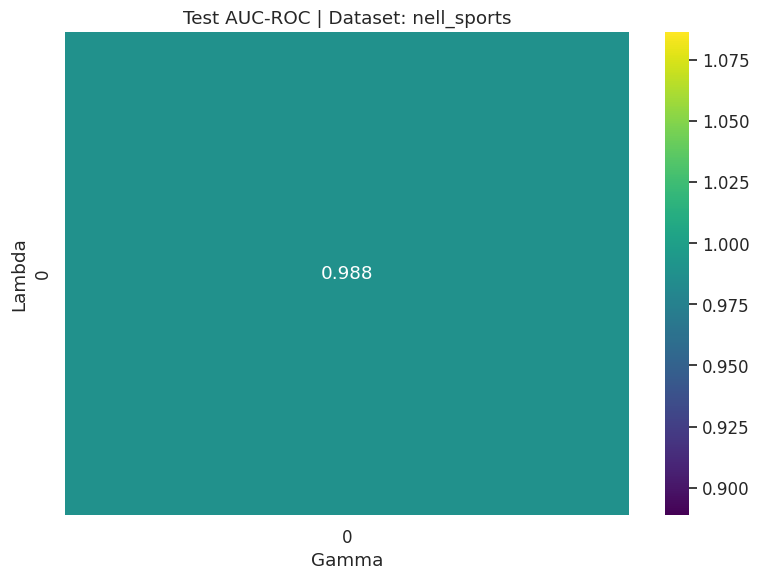


📊 Dataset: twitter


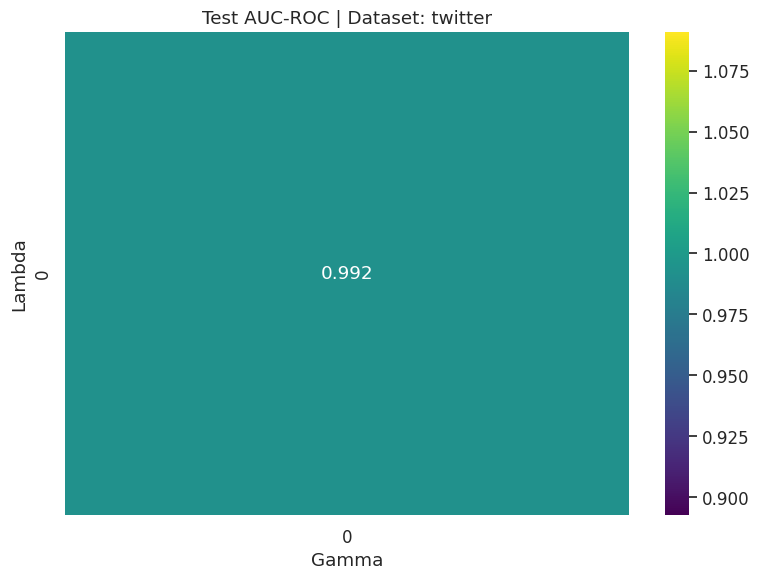


📊 Dataset: uwcse


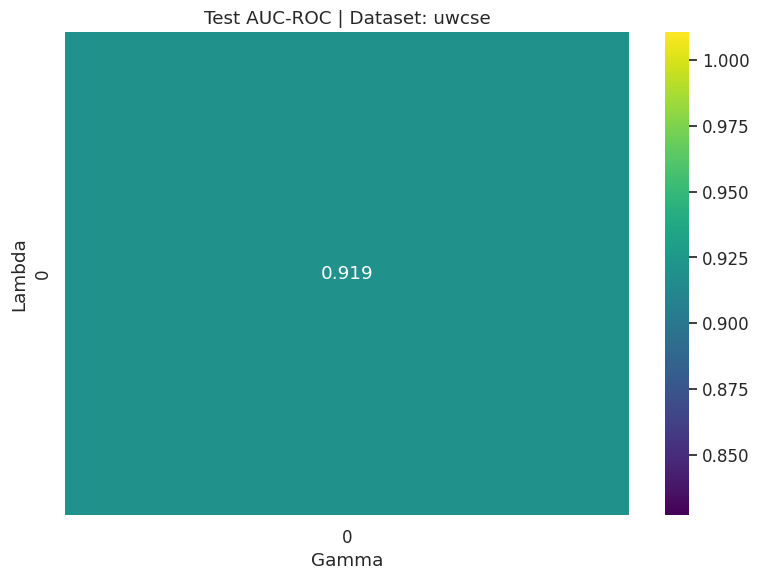


📊 Dataset: yeast


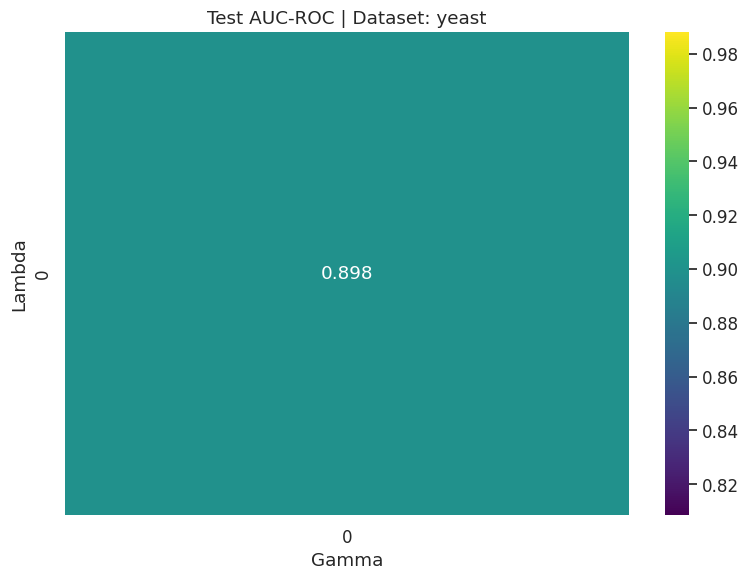

In [5]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_roc_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-ROC | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()



📊 Dataset: cora


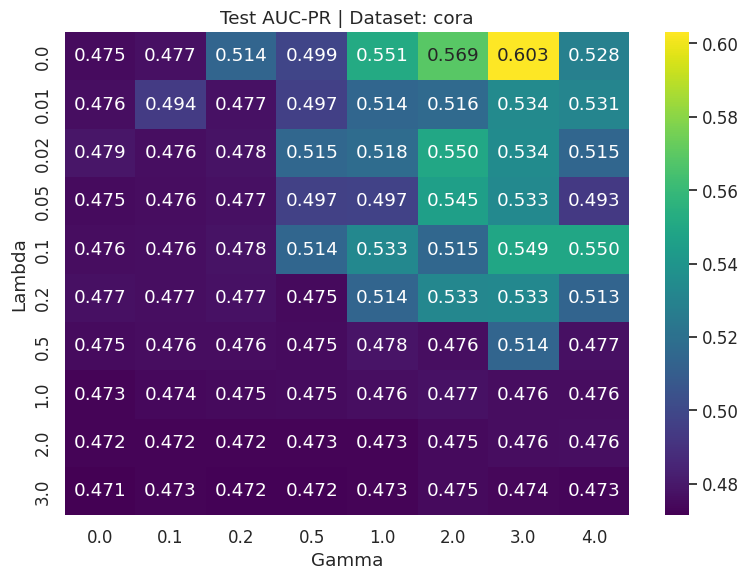


📊 Dataset: imdb


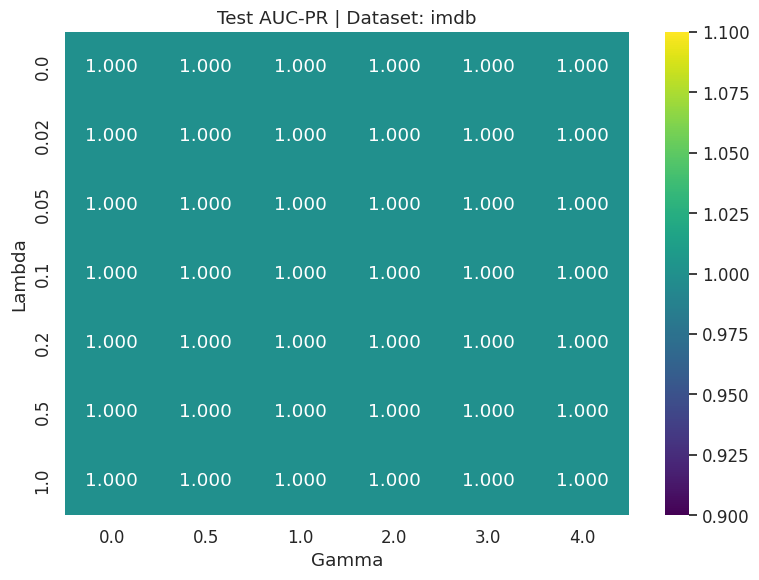


📊 Dataset: nell_finances


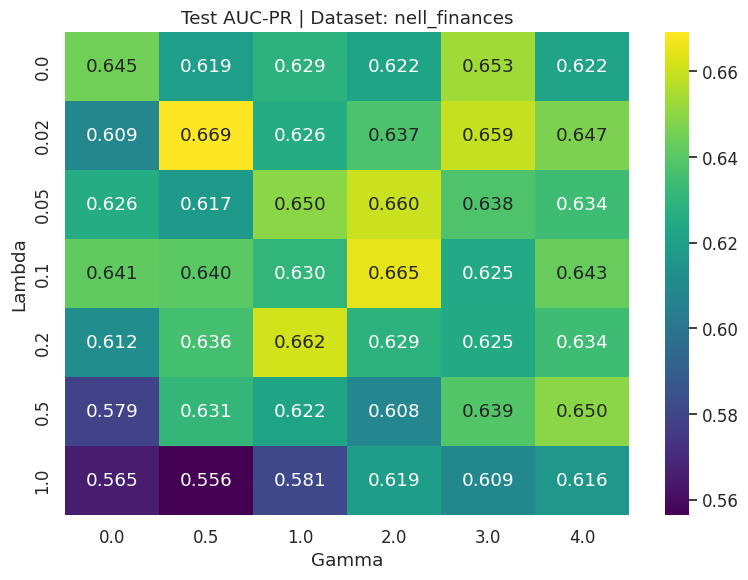


📊 Dataset: nell_sports


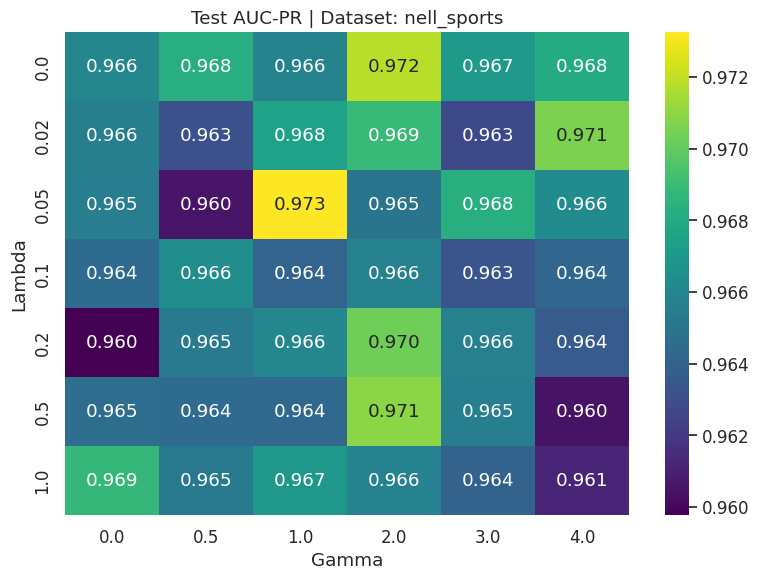


📊 Dataset: twitter


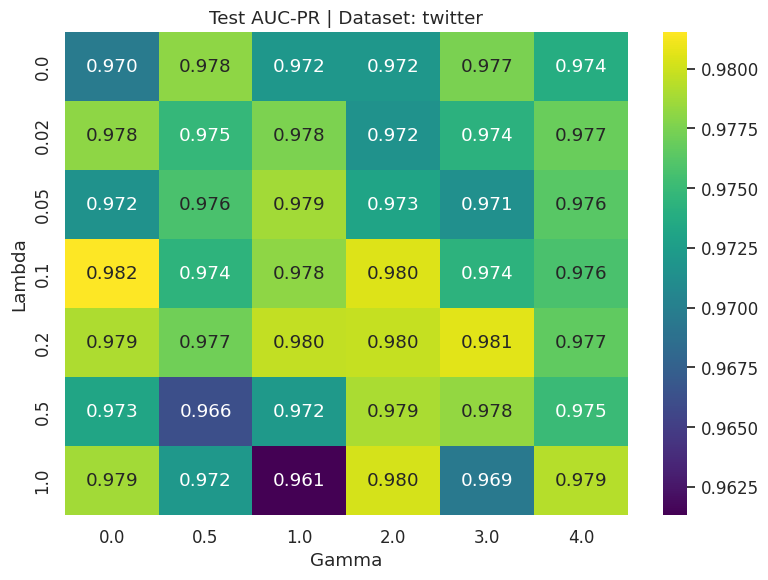


📊 Dataset: uwcse


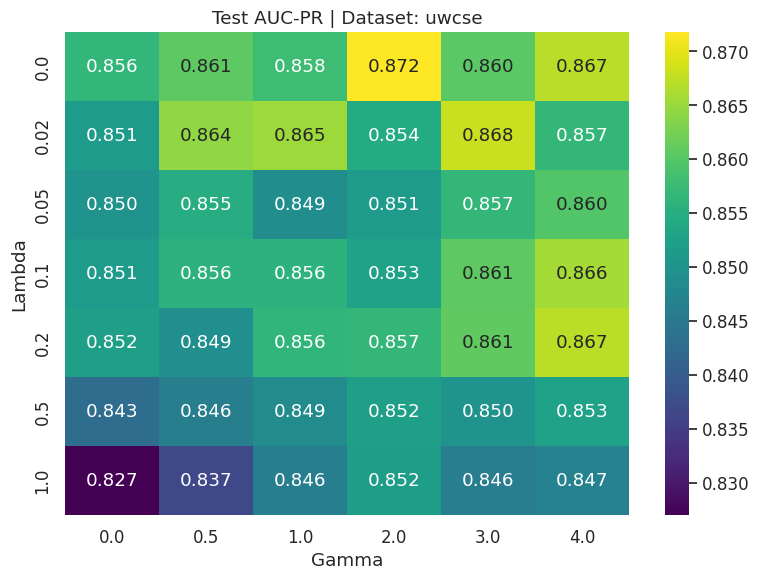


📊 Dataset: yeast


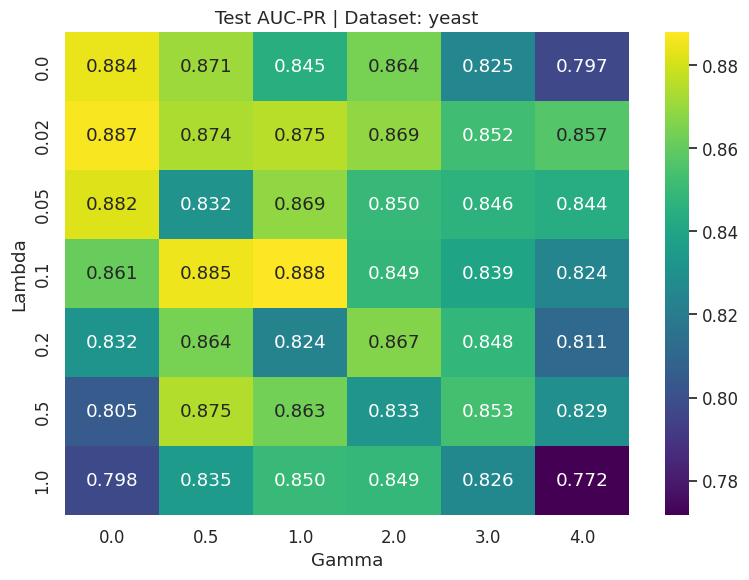

In [5]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_pr_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-PR | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


## Large Datasets - GFL RDN Boost

Check RDN simulation

In [3]:
records = []

for dataset in datasets:
    file_name = base_path / f"large_dataset_results_gfl_{dataset}_rdn_simulation.json"
    
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

# Seleciona apenas as métricas desejadas
metrics = ["train_auc_roc", "test_auc_roc", "train_auc_pr", "test_auc_pr"]
df = df[["dataset"] + metrics]

# Cria DataFrame formatado com "média ± desvio"
formatted = pd.DataFrame(index=summary.index)
formatted["dataset"] = summary["dataset"]

for metric in metrics:
    mean_col = f"{metric}_mean"
    std_col = f"{metric}_std"
    formatted[metric] = summary.apply(
        lambda row: f"{row[mean_col]:.3f} ± {row[std_col]:.3f}", axis=1
    )
formatted.reset_index(drop=True, inplace=True)
display(formatted)


,dataset,train_auc_roc,test_auc_roc,train_auc_pr,test_auc_pr
0,cora,0.573 ± 0.007,0.577 ± 0.053,0.504 ± 0.022,0.510 ± 0.110
1,imdb,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000,1.000 ± 0.000
2,nell_finances,0.758 ± 0.051,0.707 ± 0.073,0.673 ± 0.061,0.614 ± 0.090
3,nell_sports,0.999 ± 0.001,0.992 ± 0.004,0.997 ± 0.001,0.987 ± 0.007
4,twitter,0.992 ± 0.007,0.992 ± 0.005,0.985 ± 0.013,0.978 ± 0.011
5,uwcse,0.973 ± 0.005,0.936 ± 0.043,0.940 ± 0.013,0.845 ± 0.095
6,yeast,0.904 ± 0.058,0.893 ± 0.071,0.866 ± 0.070,0.849 ± 0.084


In [8]:
records = []

for dataset in datasets:
    file_name = base_path / f"large_dataset_results_gfl_{dataset}.json"
    with open(file_name, "r") as file:
        data = json.load(file)

    for exp in data:
        print(exp)
        gamma = exp.get("focal_loss_gamma")
        lambd = exp.get("boxcox_lambda")

        for r in exp.get("results", []):
            train = r.get("train", {})
            test = r.get("test", {})

            records.append({
                "dataset": dataset,
                "gamma": gamma,
                "lambda": lambd,
                "train_auc_roc": train.get("auc_roc"),
                "test_auc_roc": test.get("auc_roc"),
                "train_auc_pr": train.get("auc_pr"),
                "test_auc_pr": test.get("auc_pr"),
            })

df = pd.DataFrame(records)

# Agrupa e calcula médias e desvios
summary = df.groupby(["dataset", "gamma", "lambda"]).agg(["mean", "std"])
summary.columns = [f"{col[0]}_{col[1]}" for col in summary.columns]
summary.reset_index(inplace=True)

#display(summary.head())


{'focal_loss_gamma': 0, 'boxcox_lambda': 0, 'rdn_version': 'gflRdn', 'results': [{'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 447, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 295, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 420, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inference_time_ms': 315, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}}, {'train_folds': ['fold01', 'fold02', 'fold03', 'fold04'], 'test_folds': ['fold00'], 'train': {'inference_time_ms': 453, 'f1': 1.0, 'recall': 1.0, 'precision': 1.0, 'cll': -0.094492, 'auc_pr': 1.0, 'auc_roc': 1.0}, 'test': {'inferen


📊 Dataset: cora
cora


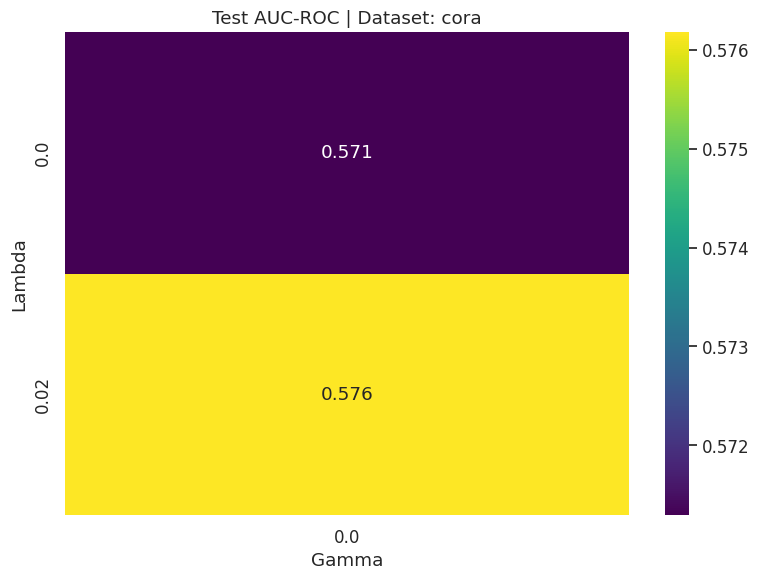


📊 Dataset: imdb
imdb


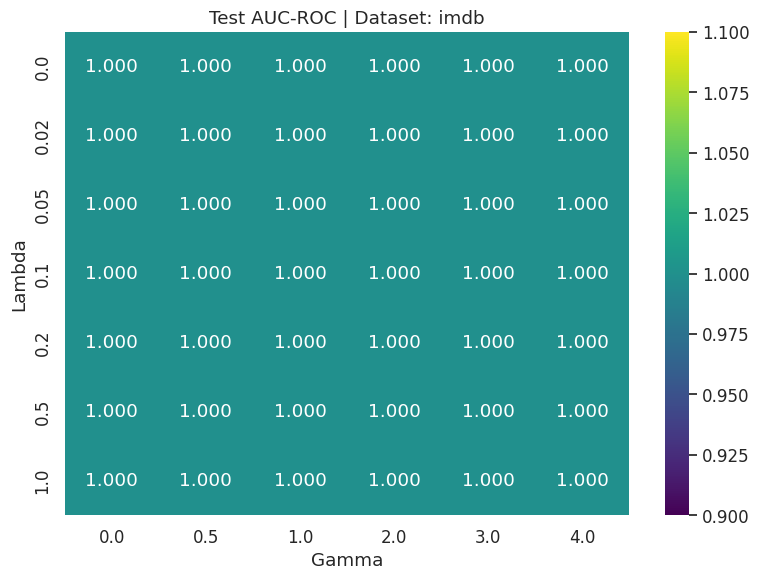


📊 Dataset: nell_finances
nell_finances


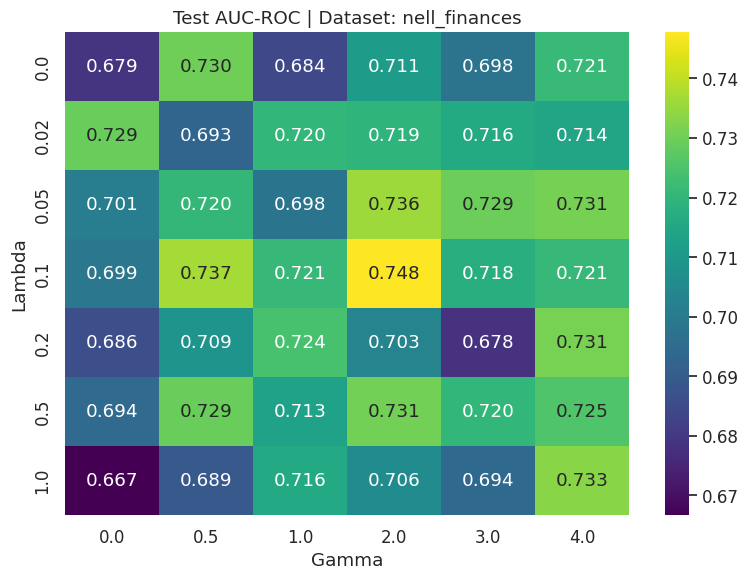


📊 Dataset: nell_sports
nell_sports


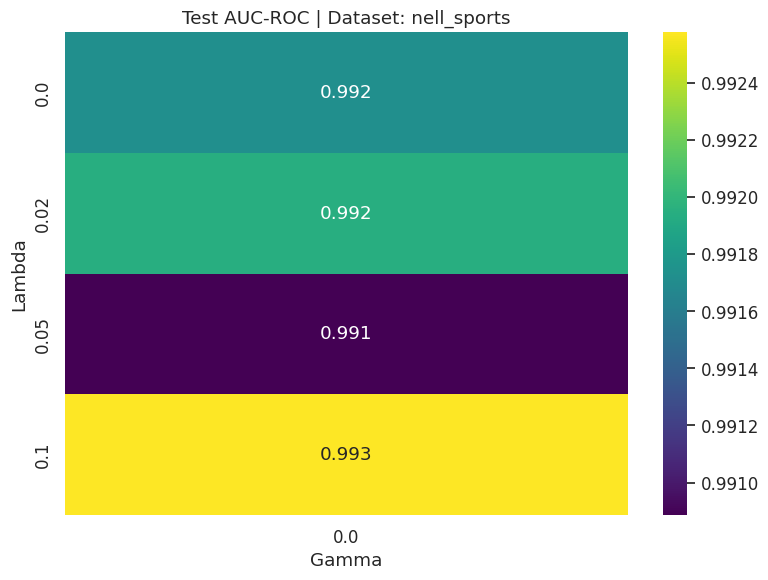


📊 Dataset: twitter
twitter


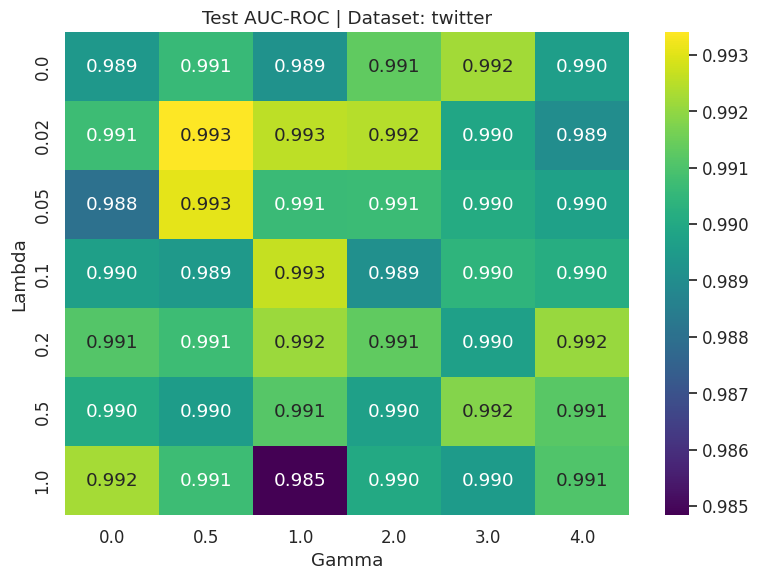


📊 Dataset: uwcse
uwcse


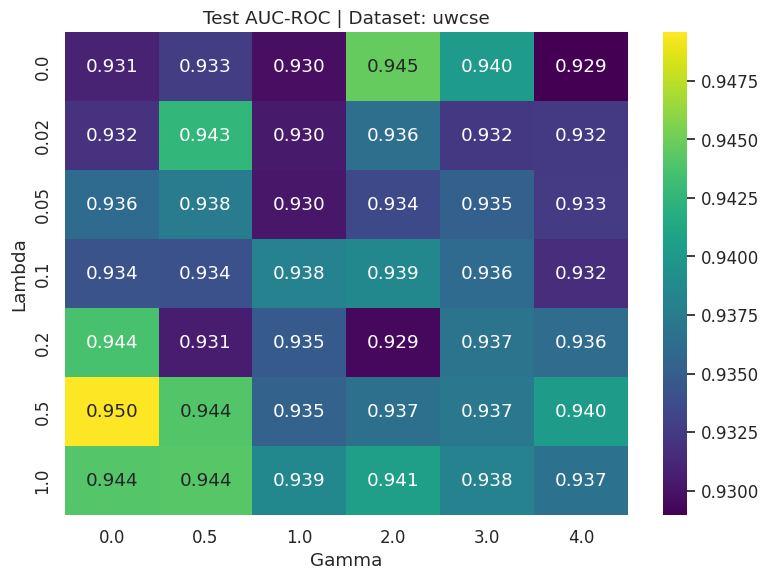


📊 Dataset: yeast
yeast


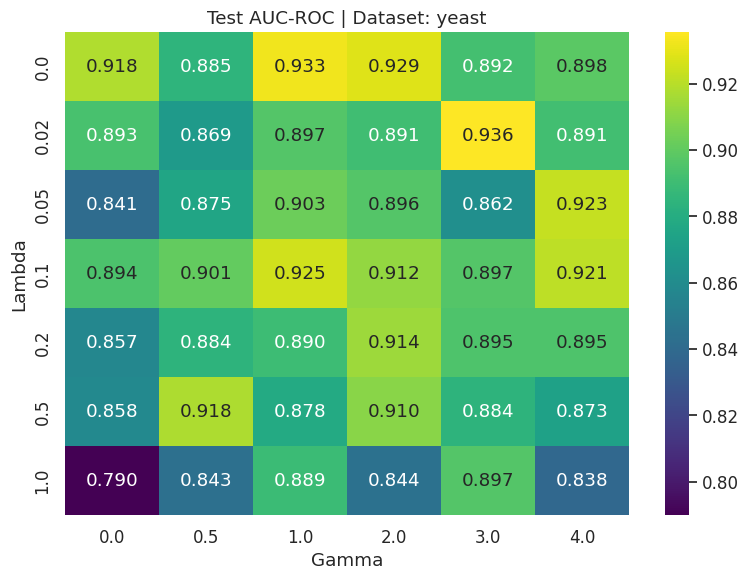

In [9]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    print(dataset)

    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_roc_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-ROC | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


In [18]:
data_ds

,dataset,gamma,lambda,train_auc_roc_mean,train_auc_roc_std,test_auc_roc_mean,test_auc_roc_std,train_auc_pr_mean,train_auc_pr_std,test_auc_pr_mean,test_auc_pr_std
0,cora,0.0,0.00,0.588358,0.050857,0.555244,0.010601,0.520528,0.128542,0.475202,0.035917
1,cora,0.0,0.01,0.588767,0.045541,0.556308,0.010687,0.521299,0.122529,0.476332,0.035366
2,cora,0.0,0.02,0.592783,0.049950,0.558598,0.012384,0.527141,0.123289,0.479049,0.037885
3,cora,0.0,0.05,0.586842,0.051568,0.555143,0.010535,0.517622,0.128062,0.475219,0.035697
4,cora,0.0,0.10,0.588029,0.049671,0.555370,0.011918,0.519665,0.130162,0.475877,0.036805
...,...,...,...,...,...,...,...,...,...,...,...
75,cora,4.0,0.20,0.638422,0.129658,0.597201,0.108729,0.583843,0.157153,0.513112,0.114700
76,cora,4.0,0.50,0.588678,0.049468,0.556566,0.009925,0.520285,0.127109,0.476672,0.034877
77,cora,4.0,1.00,0.584217,0.047297,0.555268,0.010432,0.513863,0.129508,0.475560,0.034604
78,cora,4.0,2.00,0.584599,0.046895,0.555705,0.010510,0.514453,0.128705,0.476245,0.035412


In [16]:
sns.set(style="whitegrid", font_scale=1.1)

for dataset, data_ds in summary.groupby("dataset"):
    print(f"\n📊 Dataset: {dataset}")
    
    # Agora percorremos apenas lambda e gamma
    pivot = data_ds.pivot(index="lambda", columns="gamma", values="test_auc_pr_mean")

    plt.figure(figsize=(8, 6))
    sns.heatmap(pivot, annot=True, fmt=".3f", cmap="viridis")
    plt.title(f"Test AUC-PR | Dataset: {dataset}")
    plt.xlabel("Gamma")
    plt.ylabel("Lambda")
    plt.tight_layout()
    plt.show()


- Usar a mesma versão do RDN-Boost que o Cainã usou.
- Refazer os experimentos com o RDN-Boost original (versão do Cainã) e com o RDN-Boost Alpha Fairness.
- Tentar replicar os resultados com alguma configuração do Generalized Focal Loss.
- Explorar variações nas configurações que trazem melhores resultados.